T_MSE = 0.056751 | R_MSE = 0.066257
AVT: 81.70%
NIRBR:83.34%
Sample 0 structure:TiO2 | SiO2 | TiO2 | SiO2 | SiO2 | HfO2 | SiO2 | HfO2 | TiO2 | SiO2 | TiO2 | SiO2 | TiO2


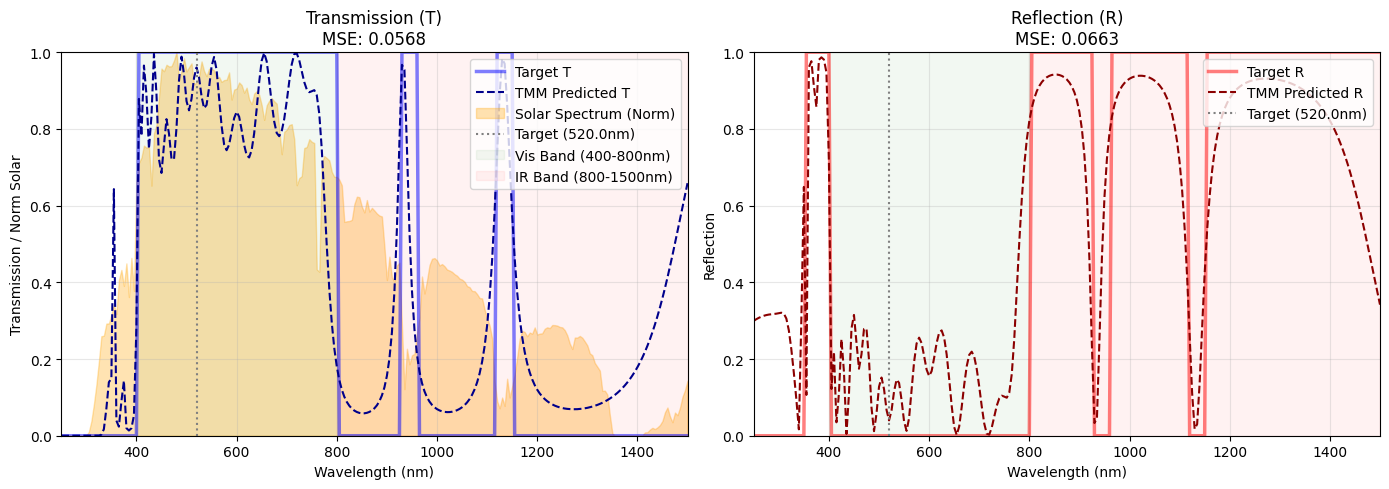

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import os
import math

N_LAYERS = 13            
N_MATERIALS = 4          
INPUT_DIM_SPECTRA = 502  
OUTPUT_DIM_STRUCT = 65   

D_MIN = 20.0             
D_MAX = 320.0            
TARGET_LAMBDA_C = 520.0  

n_incident = 1.0    
n_substrate = 1.5   
nk_file = "nk.txt"
test_data_file = "target_spectrum.npy"    
model_path = "net_inverse_5_best.pth"             
solar_file = "solar_spectrum.txt"         

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")


if not os.path.exists(nk_file):
    raise FileNotFoundError(f"cannot find{nk_file}")

nk_data = np.loadtxt(nk_file, skiprows=1)
wl_np = nk_data[:, 0]
n_np = nk_data[:, 1:1+N_MATERIALS*2:2]
k_np = nk_data[:, 2:2+N_MATERIALS*2:2]
nk_complex = (n_np - 1j * k_np).T # [4, 251]

target_idx = np.argmin(np.abs(wl_np - TARGET_LAMBDA_C))
MATERIAL_N_580 = n_np[target_idx, :]



vis_mask = (wl_np >= 400) & (wl_np <= 800)
ir_mask = (wl_np > 800) & (wl_np <= 1500)
wl_ir = wl_np[ir_mask]

calc_solar = False
if not os.path.exists(solar_file):
    print(f"cannot find {solar_file}")
else:
    solar_data = np.loadtxt(solar_file)
    solar_wl = solar_data[:, 0]
    solar_I = solar_data[:, 1]
    
   
    solar_interp = np.interp(wl_np, solar_wl, solar_I, left=0.0, right=0.0)
    solar_ir = solar_interp[ir_mask]
    

    total_ir_solar_energy = np.trapz(solar_ir, wl_ir)
    calc_solar = True


class InverseModelConstrained(nn.Module):
    def __init__(self, temperature=0.1, hidden_dims=[1024, 2048, 1024, 1024], dropout_rate=0):
        super().__init__()
        self.temperature = temperature
        
        layers = []
        curr_dim = INPUT_DIM_SPECTRA
        
        for h_dim in hidden_dims:
            layers.append(nn.Linear(curr_dim, h_dim))
            layers.append(nn.BatchNorm1d(h_dim))
            layers.append(nn.GELU())
            if dropout_rate > 0:
                layers.append(nn.Dropout(p=dropout_rate))
            curr_dim = h_dim
            
        layers.append(nn.Linear(curr_dim, N_LAYERS * N_MATERIALS))
        self.net = nn.Sequential(*layers)
        
        real_d = [TARGET_LAMBDA_C / (2.0 * n) for n in MATERIAL_N_580]
        norm_d = [(d - D_MIN) / (D_MAX - D_MIN) for d in real_d]
        
        c_mat_left = torch.eye(N_MATERIALS)
        c_mat_right = torch.tensor(norm_d, dtype=torch.float32).unsqueeze(1)
        constraint_matrix = torch.cat([c_mat_left, c_mat_right], dim=1)
        self.register_buffer('constraint_matrix', constraint_matrix)
        
    def forward(self, x):
        logits_mat = self.net(x).view(-1, N_LAYERS, N_MATERIALS)
        
        idx = torch.argmax(logits_mat, dim=-1, keepdim=True)
        probs_mat = torch.zeros_like(logits_mat).scatter_(-1, idx, 1.0)
            
        struct_5D = torch.matmul(probs_mat, self.constraint_matrix)
        struct_pred = struct_5D.view(-1, OUTPUT_DIM_STRUCT)
        return struct_pred, probs_mat 

def calculate_tmm_batch(n_struct_complex, d_physical, wl_tensor):
    B, L, W = n_struct_complex.shape
    
    n_struct_complex = n_struct_complex.to(torch.complex128)
    d_physical = d_physical.to(torch.float64)
    wl_tensor = wl_tensor.to(torch.float64)
    
    d_expanded = d_physical.unsqueeze(-1)
    delta = 2.0 * math.pi * n_struct_complex * d_expanded / wl_tensor
    cos_d = torch.cos(delta)
    sin_d = torch.sin(delta)
    
    M_total = torch.eye(2, dtype=torch.complex128, device=device)
    M_total = M_total.view(1, 1, 2, 2).expand(B, W, 2, 2).clone()
    
    for i in range(L):
        c = cos_d[:, i, :]
        s = sin_d[:, i, :]
        n_val = n_struct_complex[:, i, :]
        
        M_layer = torch.empty((B, W, 2, 2), dtype=torch.complex128, device=device)
        M_layer[..., 0, 0] = c
        M_layer[..., 0, 1] = 1j * s / n_val
        M_layer[..., 1, 0] = 1j * n_val * s
        M_layer[..., 1, 1] = c
        
        M_total = torch.matmul(M_total, M_layer)
        
    A = M_total[..., 0, 0]
    B_mat = M_total[..., 0, 1]
    C = M_total[..., 1, 0]
    D = M_total[..., 1, 1]
    
    y0, ys = float(n_incident), float(n_substrate)
    
    B_val = A + B_mat * ys
    C_val = C + D * ys
    
    r = (y0 * B_val - C_val) / (y0 * B_val + C_val)
    t = (2 * y0) / (y0 * B_val + C_val)
    
    R = torch.abs(r) ** 2
    T = (ys / y0) * torch.abs(t) ** 2
    
    return T.to(torch.float32).cpu().numpy(), R.to(torch.float32).cpu().numpy()


def main():
    if not os.path.exists(model_path):
        raise FileNotFoundError(f"cannot find {model_path}")
    if not os.path.exists(test_data_file):
        raise FileNotFoundError(f"cannot find {test_data_file}")
        


    model = InverseModelConstrained().to(device)
    model.load_state_dict(torch.load(model_path, map_location=device))
    model.eval() 

    data = np.load(test_data_file).astype(np.float32)
    num_total = data.shape[0]

    

    BATCH_SIZE = 1024
    all_mat_indices = []
    all_T_pred = []
    all_R_pred = []
    
    nk_tensor = torch.tensor(nk_complex, dtype=torch.complex128, device=device)
    n_580_tensor = torch.tensor(MATERIAL_N_580, dtype=torch.float64, device=device)
    wl_tensor = torch.tensor(wl_np, dtype=torch.float64, device=device).view(1, 1, -1)
    
    for i in range(0, num_total, BATCH_SIZE):
        batch_data = data[i:i+BATCH_SIZE]
        target_tensor = torch.tensor(batch_data, device=device)
        
        with torch.no_grad():
            _, probs_mat = model(target_tensor)
            
        mat_indices = torch.argmax(probs_mat, dim=-1)
        all_mat_indices.append(mat_indices.cpu())
        
        # --- TMM 物理再验证 ---
        n_struct_complex = nk_tensor[mat_indices]
        n_struct_580 = n_580_tensor[mat_indices]
        d_physical = TARGET_LAMBDA_C / (2.0 * n_struct_580)
        
        T_pred, R_pred = calculate_tmm_batch(n_struct_complex, d_physical, wl_tensor)
        all_T_pred.append(T_pred)
        all_R_pred.append(R_pred)
        
    mat_indices_all = torch.cat(all_mat_indices, dim=0).numpy()
    T_pred_all = np.concatenate(all_T_pred, axis=0)
    R_pred_all = np.concatenate(all_R_pred, axis=0)
    
    # --- 4. 计算全局误差与各项性能指标 ---
    T_target_all = data[:, :251]
    R_target_all = data[:, 251:]
    mse_T_global = np.mean((T_target_all - T_pred_all)**2)
    mse_R_global = np.mean((R_target_all - R_pred_all)**2)
    

    print(f"T_MSE = {mse_T_global:.6f} | R_MSE = {mse_R_global:.6f}")
    

    global_vis_T_avg = np.mean(T_pred_all[:, vis_mask]) * 100.0
    print(f"AVT: {global_vis_T_avg:.2f}%")


    if calc_solar:
        all_ir_blocked = []
        for i in range(num_total):
            T_ir_pred = T_pred_all[i][ir_mask]
            transmitted_ir_energy = np.trapz(T_ir_pred * solar_ir, wl_ir)
            ir_blocked_ratio = (1.0 - transmitted_ir_energy / total_ir_solar_energy) * 100.0
            all_ir_blocked.append(ir_blocked_ratio)
        
        avg_ir_blocked = np.mean(all_ir_blocked)
        print(f"NIRBR:{avg_ir_blocked:.2f}%")
    

    num_to_plot = min(num_total, 10) 
    random_indices = np.random.choice(num_total, num_to_plot, replace=False) if num_total > 10 else np.arange(num_total)
    
    for i, idx in enumerate(random_indices):
        fig, (ax_T, ax_R) = plt.subplots(1, 2, figsize=(14, 5))
        
        T_target = T_target_all[idx]
        R_target = R_target_all[idx]
        T_tmm = T_pred_all[idx]
        R_tmm = R_pred_all[idx]
        
        mat_seq = mat_indices_all[idx]
        M = ["SiO2","Al2O3","TiO2","HfO2"]
        struct_str = " | ".join([M[m] for m in mat_seq])
        print(f"Sample {idx} structure:{struct_str}")
        
        mse_T = np.mean((T_target - T_tmm)**2)
        mse_R = np.mean((R_target - R_tmm)**2)
        

        vis_T_mean = np.mean(T_tmm[vis_mask]) * 100.0
        title_suffix = f" | Vis T_avg: {vis_T_mean:.1f}%"
        
        if calc_solar:
            T_ir_pred = T_tmm[ir_mask]
            transmitted_ir_energy = np.trapz(T_ir_pred * solar_ir, wl_ir)
            ir_blocked_ratio = (1.0 - transmitted_ir_energy / total_ir_solar_energy) * 100.0
            title_suffix += f" | IR Blocked: {ir_blocked_ratio:.1f}%"
        

        ax_T.plot(wl_np, T_target, label='Target T', color='blue', linewidth=2.5, alpha=0.5)
        ax_T.plot(wl_np, T_tmm, label='TMM Predicted T', color='darkblue', linewidth=1.5, linestyle='--')
        

        if calc_solar:
            ax_T.fill_between(wl_np, 0, solar_interp / np.max(solar_interp), color='orange', alpha=0.3, label='Solar Spectrum (Norm)')
            
        ax_T.set_title(f'Transmission (T)\nMSE: {mse_T:.4f}')
        ax_T.axvline(x=TARGET_LAMBDA_C, color='gray', linestyle=':', label=f'Target ({TARGET_LAMBDA_C}nm)')
        

        ax_T.axvspan(400, 800, color='green', alpha=0.05, label='Vis Band (400-800nm)')
        ax_T.axvspan(800, 1500, color='red', alpha=0.05, label='IR Band (800-1500nm)') 
        
        ax_T.set_xlabel('Wavelength (nm)')
        ax_T.set_ylabel('Transmission / Norm Solar')
        ax_T.set_xlim(250, 1500)
        ax_T.set_ylim(0, 1)
        ax_T.legend(loc='upper right')
        ax_T.grid(True, alpha=0.3)
        

        ax_R.plot(wl_np, R_target, label='Target R', color='red', linewidth=2.5, alpha=0.5)
        ax_R.plot(wl_np, R_tmm, label='TMM Predicted R', color='darkred', linewidth=1.5, linestyle='--')
        ax_R.set_title(f'Reflection (R)\nMSE: {mse_R:.4f}')
        ax_R.axvline(x=TARGET_LAMBDA_C, color='gray', linestyle=':', label=f'Target ({TARGET_LAMBDA_C}nm)')
        

        ax_R.axvspan(400, 800, color='green', alpha=0.05)
        ax_R.axvspan(800, 1500, color='red', alpha=0.05)
        
        ax_R.set_xlabel('Wavelength (nm)')
        ax_R.set_ylabel('Reflection')
        ax_R.set_xlim(250, 1500)
        ax_R.set_ylim(0, 1)
        ax_R.legend(loc='upper right')
        ax_R.grid(True, alpha=0.3)


        
        plt.tight_layout()
        plt.show()

if __name__ == "__main__":
    main()